In [1]:
import numpy as np 
import pandas as pd 
import matplotlib.pyplot as plt 
from sklearn.model_selection import train_test_split 

SEED = 42 

FEATURE_COLS = ["Age", "Weight_kg", "Height_m", "Max_BPM", "Avg_BPM"
                , "Resting_BPM", "Session_Duration_min", "Fat_Percentage", "Water_Intake_liters", "BMI"] 

# the notebook is inside notebooks/, so the csv is one folder up 
df = pd.read_csv("../backend/data/gym_members_clean.csv") 

# same split for everyone in the team: 80% train / 20% test 
Xtr, Xte, yc_tr, yc_te, yr_tr, yr_te = train_test_split( 
    df[FEATURE_COLS], df["Overtraining_Risk_Label"], df["Calories_Burned"], 
    test_size=0.2, random_state=SEED, stratify=df["Overtraining_Risk_Label"]) 

print(Xtr.shape, Xte.shape)   # (778, 10) (195, 10)

import os
os.makedirs("plots", exist_ok=True)

(778, 10) (195, 10)


In [2]:
from sklearn.ensemble import IsolationForest
from sklearn.preprocessing import StandardScaler

# printing label percentage
print(f"Percentage of members at overtraining risk :  {(df["Overtraining_Risk_Label"].mean()*100):.2f}%")
print("\n------------------------------------------------------")
print("\nApproximately 65% of the dataset is labeled as at risk of overtraining (Overtraining_Risk_Label = 1) based on the project threshold rule.")
print("We've preserved this class balance across the train and test splits using 'startify'.")
print("\n------------------------------------------------------")

# scaling 
scaler = StandardScaler()
Xtr_scaled = scaler.fit_transform(Xtr)
Xte_scaled = scaler.transform(Xte)

# detecting anomalies (IsolationForest)
iso = IsolationForest(contamination=0.06, random_state=SEED)
iso_predictions = iso.fit_predict(Xtr_scaled)

anomalies = (iso_predictions == -1).sum()
print("\nDetected Anomalies in Traing Set: ", anomalies)
print("\n------------------------------------------------------")

anomalies_df = Xtr[iso_predictions == -1]
normal_df = Xtr[iso_predictions == 1]

# anomalies vs normal points
comparison = pd.DataFrame({
    "Anomalies Mean" : anomalies_df.mean(),
    "Normal Mean" : normal_df.mean()
})

print(comparison)
print("\n------------------------------------------------------")
print("\nAnomalies cases have a higher ['Weight_Kg', 'BMI'] mean, and a lower ['Session_Duration_min', 'Fat_Percentage'] mean")

Percentage of members at overtraining risk :  65.06%

------------------------------------------------------

Approximately 65% of the dataset is labeled as at risk of overtraining (Overtraining_Risk_Label = 1) based on the project threshold rule.
We've preserved this class balance across the train and test splits using 'startify'.

------------------------------------------------------

Detected Anomalies in Traing Set:  47

------------------------------------------------------
                      Anomalies Mean  Normal Mean
Age                        37.404255    38.844049
Weight_kg                  96.314894    72.166484
Height_m                    1.767234     1.719699
Max_BPM                   179.936170   179.906977
Avg_BPM                   147.489362   143.467852
Resting_BPM                62.085106    62.114911
Session_Duration_min       67.429787    75.598358
Fat_Percentage             22.214894    25.287004
Water_Intake_liters         2.861702     2.607934
BMI            

In [3]:
# training models (Dummy - Decision Tree - Random Forest)
from sklearn.dummy import DummyClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    f1_score,
    roc_auc_score,
    roc_curve,
    confusion_matrix
)

# dummy classifier
dummy_clf = DummyClassifier(strategy="most_frequent", random_state=SEED)
dummy_clf.fit(Xtr_scaled, yc_tr)
y_pred_dummy = dummy_clf.predict(Xte_scaled)
y_prob_dummy = dummy_clf.predict_proba(Xte_scaled)[:,1]

print("\n==========Dummy Classifier Metrics============")
print(f"F1 Score: {f1_score(yc_te, y_pred_dummy):.4f}")
print(f"AUC Score :  {roc_auc_score(yc_te, y_prob_dummy):.4f}")
print("Confution Matrix:\n", confusion_matrix(yc_te, y_pred_dummy))

#----------------------------------------------------------------

# decision tree classifier
dt_clf = DecisionTreeClassifier(max_depth=3, random_state=SEED)
dt_clf.fit(Xtr_scaled, yc_tr)
y_pred_dt = dt_clf.predict(Xte_scaled)
y_prob_dt = dt_clf.predict_proba(Xte_scaled)[:,1]

print("\n==========Decision Tree Metrics==============")
print(f"F1 Score: {f1_score(yc_te, y_pred_dt):.4f}")
print(f"AUC Score:  {roc_auc_score(yc_te, y_prob_dt):.4f}")
print("Confution Matrix:\n",confusion_matrix(yc_te, y_pred_dt))

#----------------------------------------------------------------

# random forest classifier
rf_clf = RandomForestClassifier(n_estimators=200, max_depth=12, class_weight="balanced", random_state=SEED)
rf_clf.fit(Xtr_scaled, yc_tr)
y_pred_rf = rf_clf.predict(Xte_scaled)
y_prob_rf = rf_clf.predict_proba(Xte_scaled)[:,1]

print("\n==========Random Forest Metrics==============")
print(f"F1 Score: {f1_score(yc_te, y_pred_rf):.4f}")
print(f"AUC Score: {roc_auc_score(yc_te, y_prob_rf):.4f}")
print("Confution Matrix:\n", confusion_matrix(yc_te, y_pred_rf))

# features importances
importances = rf_clf.feature_importances_
importances_df = pd.DataFrame({
    "Feature" : FEATURE_COLS,
    "Importance" : importances
}).sort_values(by="Importance", ascending=False).reset_index(drop=True)

importances_df.index += 1

print("\n==========Feature Imporatnce=================")
print(importances_df.head(5))


==========Dummy Classifier Metrics============
F1 Score: 0.7888
AUC Score :  0.5000
Confution Matrix:
 [[  0  68]
 [  0 127]]

==========Decision Tree Metrics==============
F1 Score: 0.9127
AUC Score:  0.9310
Confution Matrix:
 [[ 58  10]
 [ 12 115]]

==========Random Forest Metrics==============
F1 Score: 0.9440
AUC Score: 0.9773
Confution Matrix:
 [[ 63   5]
 [  9 118]]

==========Feature Imporatnce=================
                Feature  Importance
1               Max_BPM    0.384640
2                   Age    0.380501
3               Avg_BPM    0.036425
4  Session_Duration_min    0.032584
5        Fat_Percentage    0.030519


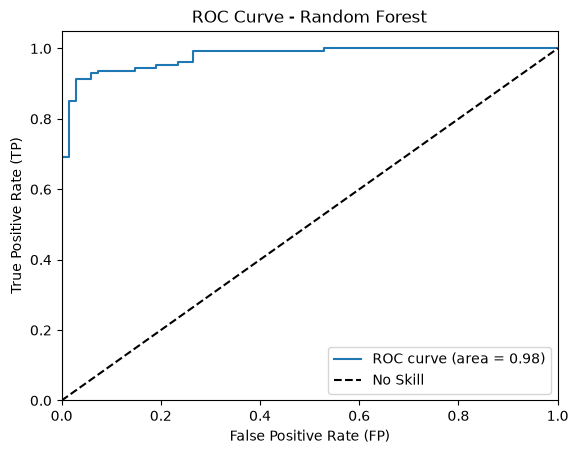

In [4]:
# calculate ROC curve for random forest 
fpr, tpr, thresholds = roc_curve(yc_te, y_prob_rf) 
roc_auc = roc_auc_score(yc_te, y_prob_rf)

# plot the ROC curve
plt.figure()  
plt.plot(fpr, tpr, label="ROC curve (area = %0.2f)" % roc_auc)
plt.plot([0, 1], [0, 1], "k--", label="No Skill")
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel("False Positive Rate (FP)")
plt.ylabel("True Positive Rate (TP)")
plt.title("ROC Curve - Random Forest")
plt.legend()
plt.show()

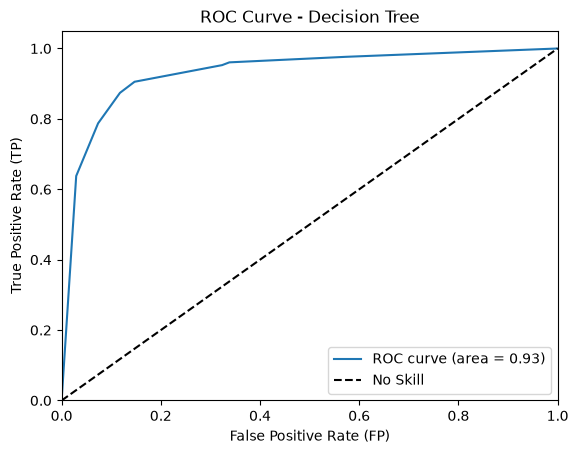

In [5]:
# calculate ROC curve for decision tree 
fpr, tpr, thresholds = roc_curve(yc_te, y_prob_dt) 
roc_auc = roc_auc_score(yc_te, y_prob_dt)

# plot the ROC curve
plt.figure()  
plt.plot(fpr, tpr, label="ROC curve (area = %0.2f)" % roc_auc)
plt.plot([0, 1], [0, 1], "k--", label="No Skill")
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel("False Positive Rate (FP)")
plt.ylabel("True Positive Rate (TP)")
plt.title("ROC Curve - Decision Tree")
plt.legend()
plt.show()

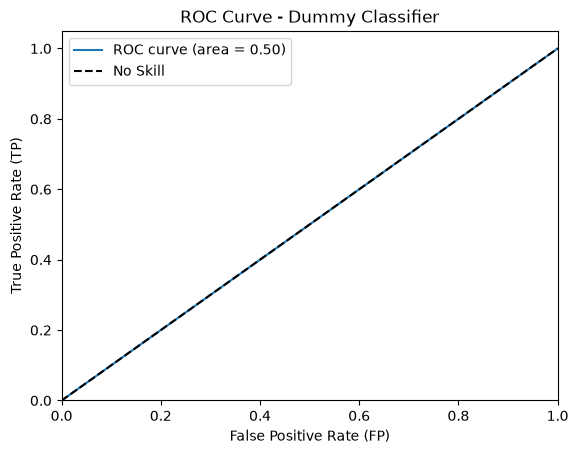

In [6]:
# calculate ROC curve for Dummy Classifier
fpr, tpr, thresholds = roc_curve(yc_te, y_prob_dummy) 
roc_auc = roc_auc_score(yc_te, y_prob_dummy)

# plot the ROC curve
plt.figure()  
plt.plot(fpr, tpr, label="ROC curve (area = %0.2f)" % roc_auc)
plt.plot([0, 1], [0, 1], "k--", label="No Skill")
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel("False Positive Rate (FP)")
plt.ylabel("True Positive Rate (TP)")
plt.title("ROC Curve - Dummy Classifier")
plt.legend()
plt.show()

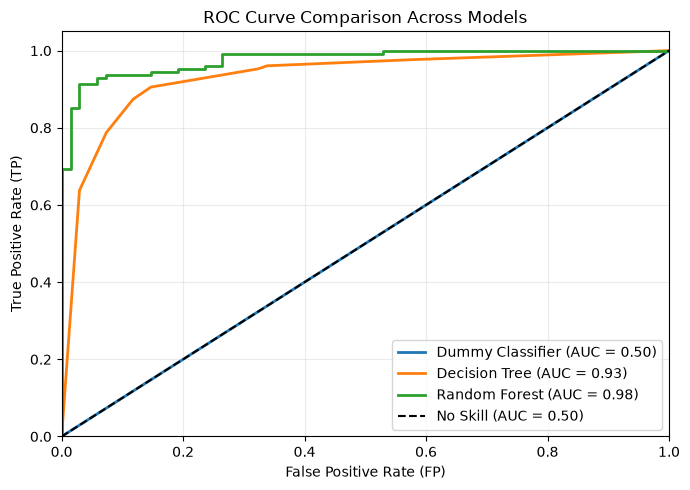

In [7]:
# a comparison plot for all models (ROC curve)
probs = {
    "Dummy Classifier" : y_prob_dummy,
    "Decision Tree" : y_prob_dt,
    "Random Forest" : y_prob_rf
}

plt.figure(figsize=(7,5))

for name, y_prob in probs.items():
    fpr, tpr, _ = roc_curve(yc_te, y_prob)
    auc = roc_auc_score(yc_te, y_prob)
    plt.plot(fpr, tpr, linewidth=2, label=f"{name} (AUC = {auc:.2f})")

plt.plot([0,1], [0,1], "k--", label="No Skill (AUC = 0.50)")

plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel("False Positive Rate (FP)")
plt.ylabel("True Positive Rate (TP)")
plt.title("ROC Curve Comparison Across Models")
plt.grid(alpha=0.25)
plt.tight_layout()
plt.legend()

plt.savefig("plots/roc_curve_comparison.png", dpi=300, bbox_inches="tight")
plt.show()

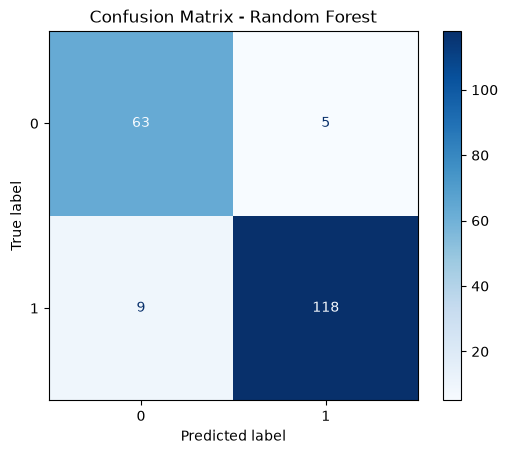

In [8]:
# confusion matrix - random forest
from sklearn.metrics import ConfusionMatrixDisplay

cm = confusion_matrix(yc_te, y_pred_rf)
disp = ConfusionMatrixDisplay(confusion_matrix=cm , display_labels=[0, 1])
disp.plot(cmap= plt.cm.Blues)
plt.title("Confusion Matrix - Random Forest")

plt.savefig("plots/confusion_matrix.png", dpi=300, bbox_inches="tight")
plt.show()

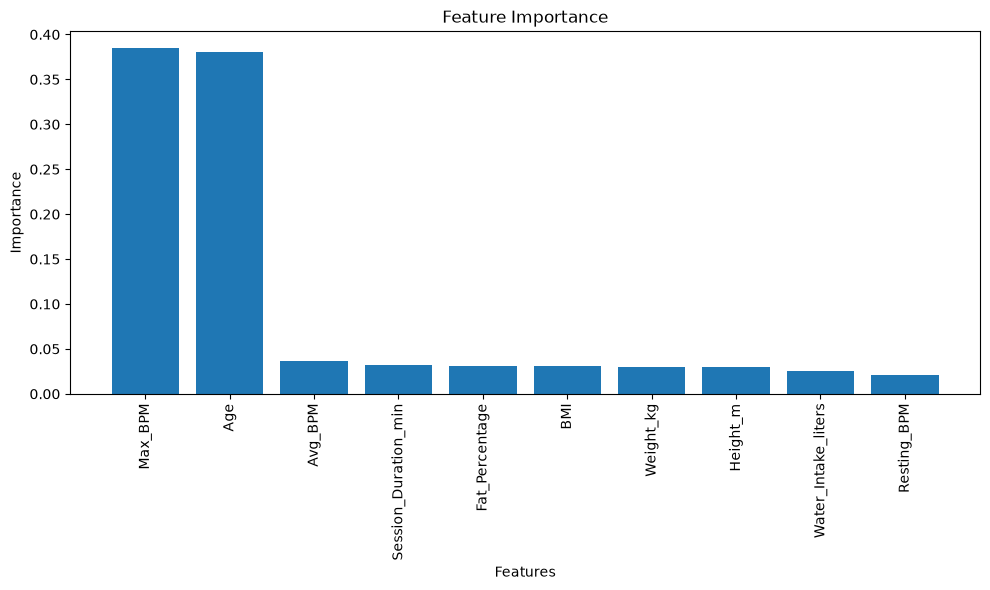

In [9]:
# features importances plot
indices = np.argsort(importances)[::-1]
names = [FEATURE_COLS[i] for i in indices]

plt.figure(figsize=(10, 6))
plt.title("Feature Importance")
plt.bar(range(Xtr_scaled.shape[1]), importances[indices])
plt.xticks(range(Xtr_scaled.shape[1]), names, rotation=90)
plt.xlabel("Features")
plt.ylabel("Importance")
plt.tight_layout()

plt.savefig("plots/feature_importance.png", dpi=300, bbox_inches="tight")
plt.show()


In [10]:
# adding (pca1, pca2, cluster_id) 
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA

kmeans = KMeans(n_clusters=3, random_state=SEED, n_init=10)
cluster_tr = kmeans.fit_predict(Xtr_scaled)
cluster_te = kmeans.predict(Xte_scaled)


pca = PCA(n_components=3, random_state=SEED)
pca_tr = pca.fit_transform(Xtr_scaled)
pca_te = pca.transform(Xte_scaled)

# taking a copy from the original data
Xtr_13 = Xtr.copy()
Xtr_13["cluster_id"] = cluster_tr
Xtr_13["pca_1"] = pca_tr[:, 0]
Xtr_13["pca_2"] = pca_tr[:, 1]


Xte_13 = Xte.copy()
Xte_13["cluster_id"] = cluster_te
Xte_13["pca_1"] = pca_te[:, 0]
Xte_13["pca_2"] = pca_te[:, 1]


print("Shapes : ", Xtr_13.shape, Xte_13.shape)


Shapes :  (778, 13) (195, 13)


In [11]:
# training random forest model on the new data (13 features)
rf_clf_13 = RandomForestClassifier(n_estimators=200, max_depth=12, class_weight="balanced", random_state=SEED)

rf_clf_13.fit(Xtr_13, yc_tr)
y_pred_13 = rf_clf_13.predict(Xte_13)
y_prob_13 = rf_clf_13.predict_proba(Xte_13)[:,1]

print(f"F1 Score (13 Features) - random Forest: {f1_score(yc_te, y_pred_13):.4f}")
print(f"AUC Score (13 Features) - Random Forest: {roc_auc_score(yc_te, y_prob_13):.4f}")

F1 Score (13 Features) - random Forest: 0.9398
AUC Score (13 Features) - Random Forest: 0.9772


In [12]:
# comparing f1-scores of random forest models (10 features vs. 13 features)
from sklearn.model_selection import StratifiedKFold, cross_val_score

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

# 10 raw features CV
cv_10 = cross_val_score(
    RandomForestClassifier(n_estimators=200, max_depth=12, class_weight="balanced", random_state=SEED),
    Xtr, yc_tr, cv=cv, scoring="f1"
)

# 13 features CV (fit scaler + PCA + KMeans inside each fold to prevent leakage)
cv_13_scores = []
for tr_idx, va_idx in cv.split(Xtr, yc_tr):

    X_f_tr, X_f_va = Xtr.iloc[tr_idx].copy(), Xtr.iloc[va_idx].copy()
    y_f_tr, y_f_va = yc_tr.iloc[tr_idx].copy(), yc_tr.iloc[va_idx].copy()

    scaler_f = StandardScaler().fit(X_f_tr)
    Xs_tr, Xs_va = scaler_f.transform(X_f_tr), scaler_f.transform(X_f_va)

    kmeans_f = KMeans(n_clusters=3, random_state=SEED, n_init=10).fit(Xs_tr)

    pca_f = PCA(n_components=3, random_state=SEED).fit(Xs_tr)

    X_f_tr["cluster_id"] = kmeans_f.predict(Xs_tr)
    X_f_tr["pca_1"], X_f_tr["pca_2"] = pca_f.transform(Xs_tr)[:,0], pca_f.transform(Xs_tr)[:,1]

    X_f_va["cluster_id"] = kmeans_f.predict(Xs_va)
    X_f_va["pca_1"], X_f_va["pca_2"] = pca_f.transform(Xs_va)[:,0], pca_f.transform(Xs_va)[:,1]

    rf_fold = RandomForestClassifier(n_estimators=200, max_depth=12, class_weight="balanced", random_state=SEED)
    rf_fold.fit(X_f_tr, y_f_tr)
    cv_13_scores.append(f1_score(y_f_va, rf_fold.predict(X_f_va)))

cv_13 = np.array(cv_13_scores)
print(f"5-Fold CV F1 Score (10 Features): {cv_10.mean():.4f} +/- {cv_10.std():.4f}")
print(f"5-Fold CV F1 SCore (13 Features): {cv_13.mean():.4f} +/- {cv_13.std():.4f}")

print("\nAdding the three featuresintroduces no new external information because they are derived from the original 10 features.")
print("Instead, they add slightly redundancy that reduces the F1 Score.")

5-Fold CV F1 Score (10 Features): 0.9651 +/- 0.0085
5-Fold CV F1 SCore (13 Features): 0.9501 +/- 0.0190

Adding the three featuresintroduces no new external information because they are derived from the original 10 features.
Instead, they add slightly redundancy that reduces the F1 Score.


In [13]:
# training random forest model with only weak features (not important)
weak_features = ["Weight_kg", "Height_m", "Fat_Percentage", "BMI"]

rf_clf_weak = RandomForestClassifier(n_estimators=200, max_depth=12, class_weight="balanced", random_state=SEED)

rf_clf_weak.fit(Xtr[weak_features], yc_tr)
y_pred_weak = rf_clf_weak.predict(Xte[weak_features])
y_prob_weak = rf_clf_weak.predict_proba(Xte[weak_features])[:,1]

print(f"F1 Score (Weak Features) : {f1_score(yc_te, y_pred_weak):.4f}")
print(f"AUC Score (Weak Features) : {roc_auc_score(yc_te, y_prob_weak):.4f}")

F1 Score (Weak Features) : 0.6586
AUC Score (Weak Features) : 0.5069


## Summary & Conclusions:
--------------------------

1. 'Overtraining_Risk_Label' does NOT represent an actual injury but its derived from a rule-based formula on : 
 (heart rate, water intake, session duration)
,so high scores mean that the models learned that rule rather than predicting an actual injury.

2. 'Decision Tree Classifier' with (max_depth=3) performs closely to 'Random Forest Classifier' with (n_estimators=200 & max_depth=12) because the underlying rule is easily captured by shallow splits.

3. The 13-feature set (pca_1, pca_2 , and cluster_id added to the 10 raw features) did not outperform the 10-feature baseline because the engineered features derive from the same underlying variables rather than adding new external information, while 'Overtraining_Risk_Label' follows direct rules on specific features that tree splits can capture more cleanly than combined/clustered projections, also adding the 3 new features increases the chance of 'Random Forest' selecting weaker or less inforamative features during random splits over the original ones.

4. Combined ROC, confusion matrix, and feature importance plots (roc_curve_comparison.png, confusion_matrix.png, feature_importance.png) clearly show model trade-offs and which features drive predictions.

5. Training only on Weight_kg, Height_m, Fat_Percentage, and BMI drops performance sharply because those columns are not the core variables defining the rule based on feature importances.